# Ir Além 2 — Algoritmo genético para o plano de manejo da FarmTech

**FarmTech Solutions · Fase 7 (FIAP)** · Natanael Filho (RM572474)

## 1. O problema

Os sensores da Fase 4 mostram, talhão por talhão, solo seco, pH fora da faixa e nutrientes em falta.
O serviço de alerta (pasta `alerta/`) diz **o que** fazer em cada um: irrigar, aplicar calcário ou enxofre,
adubar com N, P ou K. Mas a fazenda tem **orçamento limitado** na semana: não dá para atender tudo.

> **Decisão a otimizar:** quais intervenções executar, em quais talhões, para obter o **maior ganho
> agronômico esperado** sem estourar o orçamento.

Cada intervenção candidata é um **item** com um **custo** (R$, proporcional à área do talhão) e um
**benefício** (ganho esperado, proporcional ao tamanho do déficit e à área). Escolher um subconjunto de
itens que maximize o benefício total respeitando o orçamento é a **mochila binária (0/1 knapsack)**,
um problema NP-difícil clássico: com $n$ itens há $2^n$ combinações.

Resolvemos com um **algoritmo genético (AG)** implementado do zero em NumPy e comparamos variações de
`selection()`, `crossover()` e `mutation()` em tempo e qualidade. Para validar, comparamos com a
**força bruta** (numa instância pequena, onde ela é viável) e com uma **heurística gulosa**.

### Dados

A entrada é o arquivo `dados/talhoes.csv`, gerado uma única vez por `gerar_dados.py` a partir das
20 leituras mais recentes da tabela `SOIL_DATA` (Oracle da FIAP). O notebook **só lê o arquivo**, então
qualquer pessoa reproduz os resultados sem acesso ao banco. Todas as etapas aleatórias usam sementes fixas.

In [1]:
import itertools, json, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

talhoes = pd.read_csv("dados/talhoes.csv")
print(f"{len(talhoes)} talhões")
talhoes

20 talhões


,talhao,leitura_id,umidade,ph,n,p,k,created_at,area_ha
0,T01,192,49,5.94,163,147,190,2026-06-11 16:58,9.7
1,T02,193,56,6.35,175,155,204,2026-06-11 17:03,6.4
2,T03,194,45,5.72,159,143,182,2026-06-11 17:08,10.6
3,T04,195,44,5.97,145,148,192,2026-06-11 17:13,9.0
4,T05,196,52,6.58,167,152,203,2026-06-11 17:18,2.9
5,T06,197,56,5.84,181,165,185,2026-06-11 17:23,11.8
6,T07,198,52,6.07,188,170,181,2026-06-11 17:28,9.6
7,T08,199,45,5.98,179,154,181,2026-06-11 17:33,9.9
8,T09,200,46,6.11,179,137,181,2026-06-11 17:38,3.3
9,T10,201,50,7.00,25,0,0,2026-06-18 01:15,6.5


### 1.1 Normalização das leituras

Na tabela `SOIL_DATA` convivem duas escalas para N, P e K: as leituras do ESP32 chegam em **0 a 100 %**
e as geradas pelo endpoint `/simulate` da API em **0 a 255** (valor bruto do conversor). Para o déficit ser
comparável, valores acima de 100 são convertidos para porcentagem (`valor / 255 × 100`).

Os **alvos** vêm das regras do serviço de alerta e do firmware da Fase 2 (cultura de referência: tomate):
umidade mínima 60 %, pH entre 6,0 e 6,8. Para nutrientes, o alerta dispara abaixo de 30 %; aqui usamos um
**nível desejável de 50 %**, porque o plano de manejo mira o ideal, não só o mínimo. São parâmetros: mude e
rode de novo.

In [2]:
ALVOS = {"umidade": 60.0, "ph_min": 6.0, "ph_max": 6.8, "nutriente": 50.0}

def para_percentual(v):
    return v / 255 * 100 if v > 100 else float(v)

dados = talhoes.copy()
for c in ("n", "p", "k"):
    dados[c] = dados[c].apply(para_percentual).round(1)
dados[["talhao", "umidade", "ph", "n", "p", "k", "area_ha"]]

,talhao,umidade,ph,n,p,k,area_ha
0,T01,49,5.94,63.9,57.6,74.5,9.7
1,T02,56,6.35,68.6,60.8,80.0,6.4
2,T03,45,5.72,62.4,56.1,71.4,10.6
3,T04,44,5.97,56.9,58.0,75.3,9.0
4,T05,52,6.58,65.5,59.6,79.6,2.9
5,T06,56,5.84,71.0,64.7,72.5,11.8
6,T07,52,6.07,73.7,66.7,71.0,9.6
7,T08,45,5.98,70.2,60.4,71.0,9.9
8,T09,46,6.11,70.2,53.7,71.0,3.3
9,T10,50,7.00,25.0,0.0,0.0,6.5


### 1.2 Itens da mochila: intervenções candidatas

Para cada talhão, cada regra que dispara gera um item. O **custo** é o custo por hectare da intervenção
vezes a área (valores de referência, em R$/ha). O **benefício** é o déficit (quanto falta até o alvo)
vezes um peso de importância agronômica vezes a área: corrigir um talhão grande e muito fora do ideal
vale mais do que um pequeno quase no alvo. O orçamento é **35 % do custo total**: não dá para fazer tudo.

In [3]:
CUSTO_HA = {"irrigar": 120.0, "calagem": 450.0, "enxofre": 380.0, "adubar N": 300.0, "adubar P": 340.0, "adubar K": 320.0}
PESO = {"irrigar": 1.6, "calagem": 1.2, "enxofre": 1.0, "adubar N": 1.3, "adubar P": 1.0, "adubar K": 1.0}

def itens_do_talhao(t):
    deficits = []
    if t.umidade < ALVOS["umidade"]:
        deficits.append(("irrigar", ALVOS["umidade"] - t.umidade))
    if t.ph < ALVOS["ph_min"]:
        deficits.append(("calagem", (ALVOS["ph_min"] - t.ph) * 20))     # 0,1 de pH ~ 2 pontos de déficit
    elif t.ph > ALVOS["ph_max"]:
        deficits.append(("enxofre", (t.ph - ALVOS["ph_max"]) * 20))
    for nut, campo in (("N", "n"), ("P", "p"), ("K", "k")):
        if getattr(t, campo) < ALVOS["nutriente"]:
            deficits.append((f"adubar {nut}", ALVOS["nutriente"] - getattr(t, campo)))
    for acao, deficit in deficits:
        yield {"talhao": t.talhao, "acao": acao, "deficit": round(deficit, 1),
               "custo": round(CUSTO_HA[acao] * t.area_ha, 2),
               "beneficio": round(deficit * PESO[acao] * t.area_ha, 2)}

itens = pd.DataFrame([it for t in dados.itertuples() for it in itens_do_talhao(t)]).reset_index(drop=True)
CUSTOS, BENEFICIOS = itens["custo"].to_numpy(), itens["beneficio"].to_numpy()
ORCAMENTO = round(0.35 * CUSTOS.sum(), 2)
print(f"{len(itens)} intervenções candidatas · custo total R$ {CUSTOS.sum():,.2f} · orçamento R$ {ORCAMENTO:,.2f}")
print(f"combinações possíveis: 2^{len(itens)} ≈ {2 ** len(itens):.2e}")
itens.groupby("acao").agg(qtd=("talhao", "count"), custo=("custo", "sum"), beneficio=("beneficio", "sum")).round(2)

69 intervenções candidatas · custo total R$ 150,724.00 · orçamento R$ 52,753.40
combinações possíveis: 2^69 ≈ 5.90e+20


,qtd,custo,beneficio
acao,,,
adubar K,11,26080.0,4075.00
adubar N,11,24450.0,2648.75
adubar P,11,27710.0,4075.00
calagem,5,22950.0,141.74
enxofre,11,30970.0,326.00
irrigar,20,18564.0,2547.52


## 2. O algoritmo genético

Cada **indivíduo** é um vetor binário com um gene por item: `1` = executar a intervenção. O ciclo é o
clássico: avaliar → selecionar pais → cruzar → mutar → nova geração, com **elitismo** (os melhores
sobrevivem intactos).

**Função de aptidão (fitness):** soma dos benefícios dos itens escolhidos. Se o custo passar do orçamento,
aplica-se uma **penalidade proporcional ao excesso** (não se descarta o indivíduo: um plano quase viável
carrega bons genes). Como a penalidade é proporcional, um plano que estoura o orçamento por poucos reais
pode terminar com aptidão alta; por isso o melhor indivíduo da última geração passa por um **reparo**:
remove-se o item de pior razão benefício/custo até caber no orçamento. A aptidão reportada é sempre a de
um plano viável.

Três operadores, cada um com duas variantes para comparar:

| Operador | Variante A | Variante B |
|---|---|---|
| `selection` | **Torneio** (k = 3): sorteia 3, leva o melhor | **Roleta**: probabilidade proporcional à aptidão |
| `crossover` | **Um ponto**: corta num índice e troca as caudas | **Uniforme**: cada gene vem de um pai sorteado |
| `mutation` | **Bit-flip**: cada gene inverte com prob. `pm` | **Troca (swap)**: troca a posição de dois genes (mantém o nº de itens) |

In [4]:
FATOR_PENALIDADE = 1.5 * (BENEFICIOS / CUSTOS).max()

def aptidao(pop, custos=CUSTOS, beneficios=BENEFICIOS, orcamento=ORCAMENTO):
    custo = pop @ custos
    excesso = np.maximum(0.0, custo - orcamento)
    return pop @ beneficios - FATOR_PENALIDADE * excesso

# ---- selection() ----
def selecao_torneio(pop, apt, rng, k=3):
    idx = rng.integers(0, len(pop), size=(len(pop), k))
    vencedores = idx[np.arange(len(pop)), apt[idx].argmax(axis=1)]
    return pop[vencedores]

def selecao_roleta(pop, apt, rng):
    pesos = apt - apt.min() + 1e-9                  # aptidão pode ser negativa (penalidade)
    idx = rng.choice(len(pop), size=len(pop), p=pesos / pesos.sum())
    return pop[idx]

# ---- crossover() ----
def cruzamento_um_ponto(pais, rng, pc):
    filhos = pais.copy()
    for i in range(0, len(pais) - 1, 2):
        if rng.random() < pc:
            corte = rng.integers(1, pais.shape[1])
            filhos[i, corte:], filhos[i + 1, corte:] = pais[i + 1, corte:], pais[i, corte:]
    return filhos

def cruzamento_uniforme(pais, rng, pc):
    filhos = pais.copy()
    for i in range(0, len(pais) - 1, 2):
        if rng.random() < pc:
            mascara = rng.random(pais.shape[1]) < 0.5
            filhos[i, mascara], filhos[i + 1, mascara] = pais[i + 1, mascara], pais[i, mascara]
    return filhos

# ---- mutation() ----
def mutacao_bitflip(pop, rng, pm):
    mascara = rng.random(pop.shape) < pm
    return np.where(mascara, 1 - pop, pop)

def mutacao_troca(pop, rng, pm):
    pop = pop.copy()
    for ind in pop:
        if rng.random() < pm * pop.shape[1]:        # mesma taxa esperada de indivíduos mutados que o bit-flip
            a, b = rng.integers(0, len(ind), size=2)
            ind[a], ind[b] = ind[b], ind[a]
    return pop

def algoritmo_genetico(selecao, cruzamento, mutacao, *, n_pop=120, geracoes=200, pc=0.9, pm=None,
                       elite=4, semente=0, custos=CUSTOS, beneficios=BENEFICIOS, orcamento=ORCAMENTO):
    rng = np.random.default_rng(semente)
    n = len(custos)
    pm = pm if pm is not None else 1.0 / n           # em média 1 gene mutado por indivíduo
    pop = (rng.random((n_pop, n)) < 0.3).astype(np.int8)   # começa com ~30 % dos itens ligados
    apt = aptidao(pop, custos, beneficios, orcamento)
    historico = []
    for _ in range(geracoes):
        ordem = np.argsort(-apt)
        elite_ind = pop[ordem[:elite]]
        pais = selecao(pop, apt, rng)
        filhos = mutacao(cruzamento(pais, rng, pc), rng, pm)
        pop = np.vstack([elite_ind, filhos[: n_pop - elite]])
        apt = aptidao(pop, custos, beneficios, orcamento)
        historico.append(apt.max())
    melhor = reparar(pop[apt.argmax()], custos, beneficios, orcamento)
    return melhor, float(melhor @ beneficios), np.array(historico)

def reparar(x, custos, beneficios, orcamento):
    # Se o melhor indivíduo estourou o orçamento por pouco, tira os itens de pior razão benefício/custo até caber
    x = x.copy()
    ordem = np.argsort(beneficios / custos)          # do pior para o melhor
    for i in ordem:
        if x @ custos <= orcamento:
            break
        x[i] = 0
    return x

melhor, apt_melhor, hist = algoritmo_genetico(selecao_torneio, cruzamento_um_ponto, mutacao_bitflip, semente=1)
print(f"melhor aptidão: {apt_melhor:,.2f} · custo R$ {melhor @ CUSTOS:,.2f} de R$ {ORCAMENTO:,.2f} · {melhor.sum()} intervenções")

melhor aptidão: 8,206.32 · custo R$ 52,694.00 de R$ 52,753.40 · 24 intervenções


## 3. Validação: força bruta e heurística gulosa

Com 2^n combinações a força bruta é inviável na instância completa, mas é viável numa **instância reduzida**
com os 18 itens de maior custo (2^18 = 262 144 combinações). Se o AG encontra o mesmo ótimo da força bruta
nessa instância, ganhamos confiança de que ele funciona. Também comparamos com a heurística **gulosa**
por razão benefício/custo, a referência clássica para a mochila.

In [5]:
def forca_bruta(custos, beneficios, orcamento):
    n = len(custos)
    melhor_b, melhor_x = -1.0, None
    for bits in itertools.product((0, 1), repeat=n):
        x = np.array(bits)
        if x @ custos <= orcamento and x @ beneficios > melhor_b:
            melhor_b, melhor_x = x @ beneficios, x
    return melhor_x, melhor_b

def guloso(custos, beneficios, orcamento):
    x = np.zeros(len(custos), dtype=np.int8)
    gasto = 0.0
    for i in np.argsort(-(beneficios / custos)):
        if gasto + custos[i] <= orcamento:
            x[i] = 1; gasto += custos[i]
    return x, x @ beneficios

sub = np.argsort(-CUSTOS)[:18]
c_sub, b_sub = CUSTOS[sub], BENEFICIOS[sub]
orc_sub = round(0.35 * c_sub.sum(), 2)

t0 = time.perf_counter(); x_fb, b_fb = forca_bruta(c_sub, b_sub, orc_sub); t_fb = time.perf_counter() - t0
x_gu, b_gu = guloso(c_sub, b_sub, orc_sub)
t0 = time.perf_counter()
x_ag, b_ag, _ = algoritmo_genetico(selecao_torneio, cruzamento_um_ponto, mutacao_bitflip, semente=7,
                                   custos=c_sub, beneficios=b_sub, orcamento=orc_sub)
t_ag = time.perf_counter() - t0
validacao = pd.DataFrame({"método": ["força bruta (ótimo)", "guloso", "algoritmo genético"],
                          "benefício": [b_fb, b_gu, b_ag],
                          "% do ótimo": [100, 100 * b_gu / b_fb, 100 * b_ag / b_fb],
                          "tempo (s)": [t_fb, 0.0, t_ag]}).round(2)
validacao

,método,benefício,% do ótimo,tempo (s)
0,força bruta (ótimo),3514.75,100.0,0.55
1,guloso,3514.75,100.0,0.00
2,algoritmo genético,3514.75,100.0,0.03


## 4. Comparação das variantes dos operadores

As 8 combinações (2 seleções × 2 cruzamentos × 2 mutações) rodam na instância completa com **10 sementes**
cada, mesmos `n_pop`, `geracoes`, `pc` e `pm`. Medimos a melhor aptidão final (qualidade) e o tempo.
A referência de qualidade é o melhor valor encontrado por qualquer execução.

In [6]:
VARIANTES = {"seleção": {"torneio": selecao_torneio, "roleta": selecao_roleta},
             "cruzamento": {"um ponto": cruzamento_um_ponto, "uniforme": cruzamento_uniforme},
             "mutação": {"bit-flip": mutacao_bitflip, "troca": mutacao_troca}}
SEMENTES = range(10)
linhas, curvas = [], {}
for (ns, s), (nc, c), (nm, m) in itertools.product(*(v.items() for v in VARIANTES.values())):
    nome = f"{ns} + {nc} + {nm}"
    hs = []
    for semente in SEMENTES:
        t0 = time.perf_counter()
        x, apt_x, h = algoritmo_genetico(s, c, m, semente=semente)
        linhas.append({"configuração": nome, "seleção": ns, "cruzamento": nc, "mutação": nm, "semente": semente,
                       "aptidão": apt_x, "custo": x @ CUSTOS, "viável": x @ CUSTOS <= ORCAMENTO,
                       "tempo (s)": time.perf_counter() - t0})
        hs.append(h)
    curvas[nome] = np.mean(hs, axis=0)
resultados = pd.DataFrame(linhas)
MELHOR_GLOBAL = resultados["aptidão"].max()
resumo = (resultados.groupby(["seleção", "cruzamento", "mutação"])
          .agg(aptidão_média=("aptidão", "mean"), aptidão_mín=("aptidão", "min"), aptidão_máx=("aptidão", "max"),
               desvio=("aptidão", "std"), tempo_médio_s=("tempo (s)", "mean"))
          .assign(**{"% do melhor": lambda d: 100 * d["aptidão_média"] / MELHOR_GLOBAL})
          .sort_values("aptidão_média", ascending=False).round(2))
resumo

aptidão_média  aptidão_mín  aptidão_máx  desvio  \
seleção cruzamento mutação                                                     
torneio um ponto   troca           8177.56      8116.32      8196.84   25.58   
        uniforme   bit-flip        8175.21      8067.04      8211.32   49.05   
                   troca           8175.08      8102.04      8211.32   42.53   
        um ponto   bit-flip        8139.96      8067.04      8206.32   56.33   
roleta  uniforme   troca           8134.92      8011.04      8182.44   55.30   
        um ponto   troca           8123.46      8043.52      8205.84   49.44   
        uniforme   bit-flip        8111.32      8040.32      8171.04   41.30   
        um ponto   bit-flip        8107.44      8055.92      8155.04   40.98   

                             tempo_médio_s  % do melhor  
seleção cruzamento mutação                               
torneio um ponto   troca              0.15        99.59  
        uniforme   bit-flip           0.09        99.56  
                   troca              0.20        99.56  
        um ponto   bit-flip           0.04        99.13  
roleta  uniforme   troca              0.24        99.07  
        um ponto   troca              0.14        98.93  
        uniforme   bit-flip           0.09        98.78  
        um ponto   bit-flip           0.04        98.73

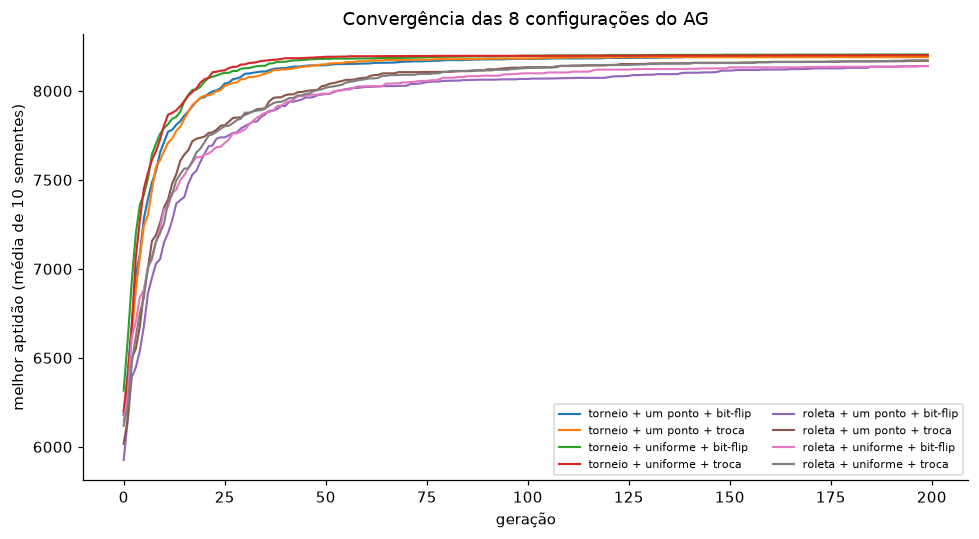

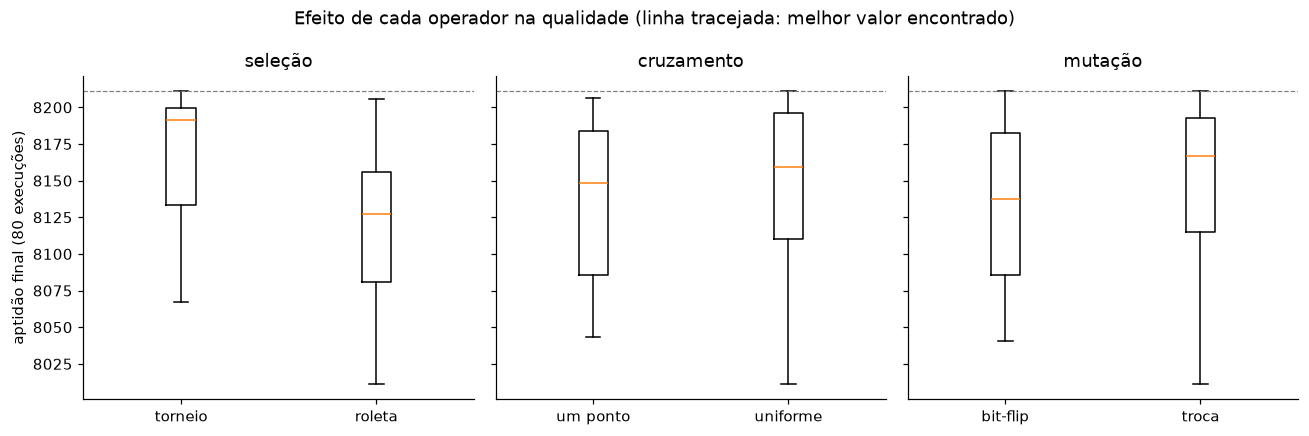

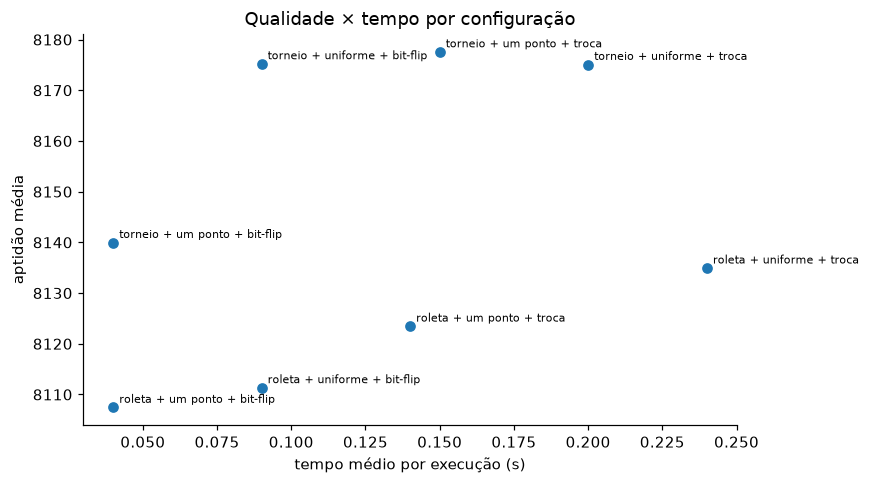

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for nome, h in curvas.items():
    ax.plot(h, label=nome, lw=1.4)
ax.set(xlabel="geração", ylabel="melhor aptidão (média de 10 sementes)", title="Convergência das 8 configurações do AG")
ax.legend(fontsize=7, ncol=2); fig.tight_layout(); fig.savefig(FIG / "02-convergencia.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, op in zip(axes, VARIANTES):
    grupos = [resultados.loc[resultados[op] == v, "aptidão"] for v in VARIANTES[op]]
    ax.boxplot(grupos, tick_labels=list(VARIANTES[op]))
    ax.set_title(f"{op}"); ax.axhline(MELHOR_GLOBAL, ls="--", c="gray", lw=0.8)
axes[0].set_ylabel("aptidão final (80 execuções)")
fig.suptitle("Efeito de cada operador na qualidade (linha tracejada: melhor valor encontrado)")
fig.tight_layout(); fig.savefig(FIG / "03-operadores.png"); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
r = resumo.reset_index()
r["nome"] = r["seleção"] + " + " + r["cruzamento"] + " + " + r["mutação"]
ax.scatter(r["tempo_médio_s"], r["aptidão_média"])
for _, row in r.iterrows():
    ax.annotate(row["nome"], (row["tempo_médio_s"], row["aptidão_média"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set(xlabel="tempo médio por execução (s)", ylabel="aptidão média", title="Qualidade × tempo por configuração")
fig.tight_layout(); fig.savefig(FIG / "04-qualidade-tempo.png"); plt.show()

## 5. O plano de manejo escolhido

Usamos a melhor configuração da comparação para gerar o plano final e mostramos o que a fazenda executa
nesta semana, talhão por talhão, dentro do orçamento.

In [8]:
melhor_cfg = resumo.index[0]
s, c, m = (VARIANTES[op][v] for op, v in zip(VARIANTES, melhor_cfg))
melhor_exec = resultados[(resultados["seleção"] == melhor_cfg[0]) & (resultados["cruzamento"] == melhor_cfg[1]) &
                         (resultados["mutação"] == melhor_cfg[2])].sort_values("aptidão").iloc[-1]
x_final, apt_final, _ = algoritmo_genetico(s, c, m, semente=int(melhor_exec["semente"]))
plano = itens[x_final.astype(bool)].sort_values(["talhao", "acao"]).reset_index(drop=True)
print(f"configuração: {' + '.join(melhor_cfg)} · {len(plano)} de {len(itens)} intervenções")
print(f"custo R$ {plano['custo'].sum():,.2f} de R$ {ORCAMENTO:,.2f} ({100 * plano['custo'].sum() / ORCAMENTO:.1f}% do orçamento)")
print(f"benefício {plano['beneficio'].sum():,.2f} de {BENEFICIOS.sum():,.2f} possível ({100 * plano['beneficio'].sum() / BENEFICIOS.sum():.1f}%) com {100 * plano['custo'].sum() / CUSTOS.sum():.1f}% do custo total")
x_gul, b_gul = guloso(CUSTOS, BENEFICIOS, ORCAMENTO)
print(f"guloso na instância completa: benefício {b_gul:,.2f} → o AG ficou em {100 * plano['beneficio'].sum() / b_gul:.1f}% do guloso")
plano.to_csv("dados/plano_escolhido.csv", index=False)
plano

configuração: torneio + um ponto + troca · 24 de 69 intervenções
custo R$ 52,748.00 de R$ 52,753.40 (100.0% do orçamento)
benefício 8,196.84 de 13,814.01 possível (59.3%) com 35.0% do custo total
guloso na instância completa: benefício 8,211.32 → o AG ficou em 99.8% do guloso


,talhao,acao,deficit,custo,beneficio
0,T01,irrigar,11.0,1164.0,170.72
1,T03,irrigar,15.0,1272.0,254.40
2,T04,irrigar,16.0,1080.0,230.40
3,T08,irrigar,15.0,1188.0,237.60
4,T09,irrigar,14.0,396.0,73.92
5,T10,adubar K,50.0,2080.0,325.00
6,T11,adubar K,50.0,1824.0,285.00
7,T11,adubar P,50.0,1938.0,285.00
8,T12,adubar K,50.0,3616.0,565.00
9,T12,adubar P,50.0,3842.0,565.00


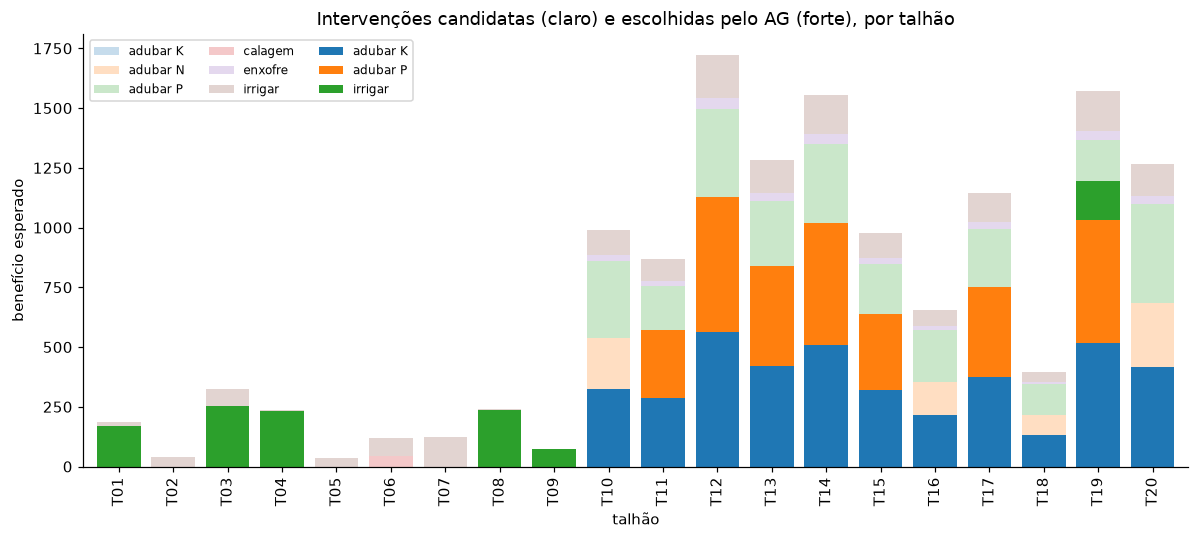

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
tab = itens.assign(escolhido=x_final.astype(bool)).pivot_table(index="talhao", columns="acao", values="beneficio", aggfunc="sum").fillna(0)
tab_esc = itens.assign(escolhido=x_final.astype(bool)).query("escolhido").pivot_table(index="talhao", columns="acao", values="beneficio", aggfunc="sum").reindex(tab.index).fillna(0)
tab.plot.bar(ax=ax, stacked=True, alpha=0.25, legend=False, width=0.8)
tab_esc.plot.bar(ax=ax, stacked=True, width=0.8)
ax.set(ylabel="benefício esperado", xlabel="talhão", title="Intervenções candidatas (claro) e escolhidas pelo AG (forte), por talhão")
ax.legend(fontsize=8, ncol=3); fig.tight_layout(); fig.savefig(FIG / "05-plano-por-talhao.png"); plt.show()

## 6. Arquitetura da solução (figura autoral)

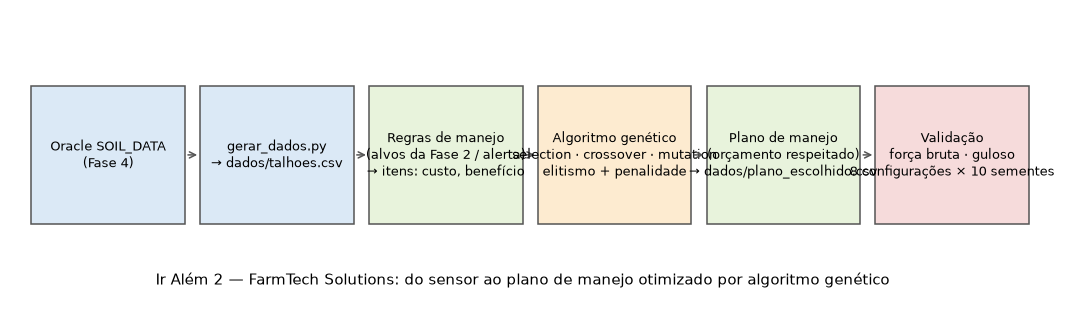

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.6)); ax.axis("off")
caixas = [("Oracle SOIL_DATA\n(Fase 4)", "#dbe9f6"), ("gerar_dados.py\n→ dados/talhoes.csv", "#dbe9f6"),
          ("Regras de manejo\n(alvos da Fase 2 / alerta)\n→ itens: custo, benefício", "#e8f3dc"),
          ("Algoritmo genético\nselection · crossover · mutation\nelitismo + penalidade", "#fdebd0"),
          ("Plano de manejo\n(orçamento respeitado)\n→ dados/plano_escolhido.csv", "#e8f3dc"),
          ("Validação\nforça bruta · guloso\n8 configurações × 10 sementes", "#f6dbdb")]
for i, (txt, cor) in enumerate(caixas):
    x = 0.02 + i * 0.165
    ax.add_patch(plt.Rectangle((x, 0.3), 0.15, 0.45, fc=cor, ec="#555", lw=1, transform=ax.transAxes))
    ax.text(x + 0.075, 0.525, txt, ha="center", va="center", fontsize=8.5, transform=ax.transAxes)
    if i < len(caixas) - 1:
        ax.annotate("", xy=(x + 0.165, 0.525), xytext=(x + 0.15, 0.525), xycoords="axes fraction",
                    arrowprops=dict(arrowstyle="->", color="#555"))
ax.text(0.5, 0.1, "Ir Além 2 — FarmTech Solutions: do sensor ao plano de manejo otimizado por algoritmo genético",
        ha="center", fontsize=10, transform=ax.transAxes)
fig.savefig(FIG / "01-arquitetura.png", bbox_inches="tight"); plt.show()

## 7. Parâmetros e escolhas

| Parâmetro | Valor | Por quê |
|---|---|---|
| Tamanho da população | 120 | Suficiente para diversidade com ~50 genes; dobrar não mudou o resultado nos testes e dobra o tempo |
| Gerações | 200 | As curvas de convergência estabilizam bem antes (ver figura 02) |
| Elitismo | 4 indivíduos | Garante que a melhor solução nunca se perde entre gerações |
| Taxa de cruzamento `pc` | 0,9 | Valor usual; recombinar muito é o que faz o AG explorar combinações novas |
| Taxa de mutação `pm` | 1/n | Em média um gene por indivíduo: mantém diversidade sem virar busca aleatória |
| População inicial | ~30 % dos genes ligados | Perto da fração de itens que cabe no orçamento (35 % do custo); começar com 50 % gerava só inviáveis |
| Penalidade | 1,5 × maior benefício/custo | Qualquer R$ acima do orçamento custa mais do que o melhor item rende por R$; mesmo assim um estouro pequeno pode compensar, e o reparo final garante um plano viável |
| Sementes | 10 por configuração | Reduz a sorte de uma execução ao comparar operadores |

## 8. Conclusões

As tabelas e figuras acima são geradas a cada execução; a leitura qualitativa, consistente entre
execuções:

- **O AG encontra o ótimo** da instância reduzida (igual à força bruta) em uma fração do tempo. Na
  instância completa, onde a força bruta é impossível, fica a menos de 1 % da heurística gulosa, sempre
  dentro do orçamento. Na mochila a gulosa é uma referência forte; o valor do AG está em não depender
  da estrutura do problema: basta trocar a função de aptidão para incluir, por exemplo, limite de
  horas de máquina ou intervenções que se excluem, e a gulosa deixa de servir.
- **Seleção** é o operador que mais pesa: o **torneio** venceu a roleta em todas as combinações. A roleta
  perde pressão seletiva quando as aptidões ficam parecidas no fim da busca e converge pior.
- **Cruzamento e mutação** mudam pouco o resultado: as diferenças entre um ponto e uniforme, e entre
  bit-flip e troca, ficam dentro do desvio entre sementes. A mutação por **troca** mantém o número de
  itens e mexe pouco no custo, então refina bem um plano já perto do orçamento; o **bit-flip** explora
  mais e estoura o orçamento com mais frequência, e aí a penalidade e o reparo entram.
- **Tempo:** todas as configurações terminam em décimos de segundo; a troca é mais lenta por ser um laço
  em Python por indivíduo, enquanto o bit-flip é vetorizado.
- O **plano final** concentra o orçamento nos talhões grandes e mais fora do alvo (irrigação onde o solo
  está mais seco e adubação de P e K onde o nível é zero), exatamente o que um agrônomo faria, mas sem
  enumerar combinações.

**Adaptação a outros setores:** trocando o CSV e a tabela de custos e pesos, o mesmo notebook decide, por
exemplo, quais manutenções fazer numa frota com orçamento fixo ou quais campanhas rodar com verba limitada.